In [1]:
import numpy as np
#농어의 길이와 무게
perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# np.array: 파이썬 리스트 등을 NumPy 배열로 변환한다.


In [2]:
#학습데이터와 테스트데이터 생성
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, random_state=42)
print(train_input.shape, test_input.shape)
train_input = train_input.reshape(-1,1)
test_input = test_input.reshape(-1,1)
print(train_input.shape, test_input.shape)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# train_test_split(X, y, ...): 입력 X와 정답 y를 같은 인덱스로 분할해 훈련·테스트 세트를 만든다.
# random_state: 데이터 분할의 난수 상태를 고정해 반복 실행 시 같은 분할을 재현한다.
# reshape(-1, 1): 1차원 길이 데이터를 한 열을 가진 2차원 입력으로 바꾼다.
# shape: NumPy 배열의 차원별 크기를 보여준다. 예: (42, 1)은 42행 1열.


(42,) (14,)
(42, 1) (14, 1)


In [3]:
#선형회귀모델 생성
#y = ax + b (x:입력, y:결과, a(coef_),b(intercept_)를 구하는 모델)
from sklearn.linear_model import LinearRegression
import numpy as np

lr = LinearRegression()
lr.fit(train_input, train_target)
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

print(lr.coef_, lr.intercept_)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# LinearRegression: 입력 특성과 결과의 관계를 선형 결합으로 학습한다. 다항 특성에도 같은 모델을 사용한다.
# fit(X, y): 입력 데이터와 정답을 바탕으로 모델을 훈련한다.
# score(X, y): 분류에서는 정확도, 회귀에서는 결정계수 R²를 반환한다.
# coef_: 선형(다항) 회귀가 학습한 각 특성의 계수. 끝에 밑줄(_)이 붙는다.
# intercept_: 선형(다항) 회귀가 학습한 절편. 끝에 밑줄(_)이 붙는다.


0.939846333997604
0.8247503123313558
[39.01714496] -709.0186449535477


In [4]:
#샘플에 대한 예측결과
sample = np.array([[50]])
pred = lr.predict(sample)
print(pred, lr.coef_*sample + lr.intercept_)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# predict(X): 학습된 모델이 입력 샘플의 클래스 또는 연속값을 예측한다.


[1241.83860323] [[1241.83860323]]


In [5]:
#테스트 데이터에 대한 예측결과
test_predict = lr.predict(test_input)
pred_target = np.column_stack((test_predict, test_target))
print(pred_target)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# np.column_stack: 배열들을 열 방향으로 이어 각 샘플의 특성 열을 구성한다.


[[-381.27462726    5.9       ]
 [  -6.71003561  100.        ]
 [ 363.95284155  250.        ]
 [ 122.04654277  130.        ]
 [ 168.86711673  130.        ]
 [ 851.66715359  820.        ]
 [ 461.49570396  320.        ]
 [ 250.80312115  188.        ]
 [ 812.65000863  900.        ]
 [ 110.34139928  125.        ]
 [ 988.22716096 1000.        ]
 [ -76.94089654   51.5       ]
 [ 383.46141403  250.        ]
 [ 356.14941255  300.        ]]


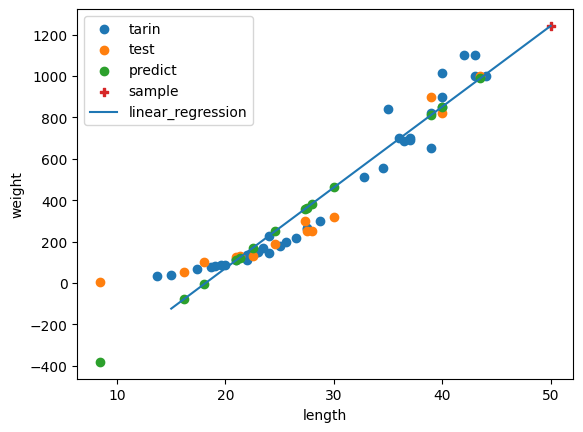

In [6]:
import matplotlib.pyplot as plt

plt.scatter(train_input, train_target, label='tarin')
plt.scatter(test_input, test_target, label='test')
plt.scatter(test_input, test_predict, label = 'predict')
plt.scatter(sample,pred,marker='P', label='sample')
plt.plot([15,50],[lr.coef_[0]*15+lr.intercept_,lr.coef_[0]*50+lr.intercept_],label='linear_regression')
plt.legend()
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# plt.scatter(x, y): 실제 데이터/예측 데이터를 산점도로 나타낸다.
# plt.plot(x, y): 선형·2차 다항 회귀의 추세선을 그린다.
# plt.show(): 지금까지 만든 그래프를 출력한다.


In [7]:
#다항회귀
#항을 2개로 증가: 길이의 제곱항, 길이
train_poly = np.column_stack((train_input **2, train_input))
test_poly = np.column_stack((test_input**2, test_input))
#모델 재훈련
lr.fit(train_poly, train_target)
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))
print(lr.coef_, lr.intercept_) #다항회귀 결과 나온 coef_와 intercept_
#샘플 예측결과
sample = np.array([[5]])
sample_poly = np.column_stack((sample ** 2, sample))
pred = lr.predict(sample_poly)
print(pred)
#테스트 예측결과
test_pred = lr.predict(test_poly)
print(test_pred)

# ─── 중간고사 학습 주석 (수정본) ───
# [오류 수정] 미완성 대입문을 sample의 제곱·원래값을 합친 다항 특성 및 예측 코드로 완성했습니다. 원래 sample=5는 그대로 유지했습니다.


0.9706807451768623
0.9775935108325122
[  1.01433211 -21.55792498] 116.05021078278264
[33.61888862]
[   6.5349146    56.6511646   290.29593158  117.05874344  144.50252913
  876.66458663  382.21135986  199.55847561  818.09027497  110.65424646
 1097.65040817   33.01314491  307.66468513  283.49043666]


50cm 다항회귀 예측: [1573.98423528]


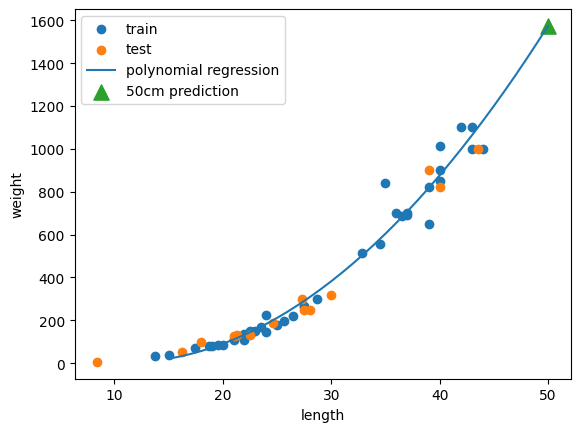

poly train R2: 0.9706807451768623
poly test R2: 0.9775935108325122


In [8]:
#재학습 모델 그래프
# [온라인 5주차 보충] 오프라인 마지막에 비어 있던 다항회귀 그래프 완성
# 위에서 lr.fit(train_poly, train_target)으로 2차 다항회귀 모델을 학습했다.

# ① 온라인 예제의 길이 50cm 농어를 새로 예측한다.
# 오프라인 실습의 sample = [[5]] 코드는 변경하지 않는다.
sample_50 = np.array([[50]])
sample_50_poly = np.column_stack((sample_50 ** 2, sample_50))
pred_50 = lr.predict(sample_50_poly)
print('50cm 다항회귀 예측:', pred_50)

# ② 15~50의 x값을 준비하여 2차 곡선 y = ax² + bx + c를 그린다.
# np.arange(15, 51)은 15부터 50까지이며 51은 포함하지 않는다.
point = np.arange(15, 51)
curve = lr.coef_[0] * point ** 2 + lr.coef_[1] * point + lr.intercept_

# ③ 실제 학습 데이터(점), 모델 곡선(선), 50cm 예측값(삼각형)을 비교한다.
plt.scatter(train_input, train_target, label='train')
plt.scatter(test_input, test_target, label='test')
plt.plot(point, curve, label='polynomial regression')
plt.scatter(sample_50[0, 0], pred_50[0], marker='^', s=120, label='50cm prediction')
plt.xlabel('length')
plt.ylabel('weight')
plt.legend()
plt.show()

# ④ 회귀 score()의 결과는 결정계수 R²이다.
print('poly train R2:', lr.score(train_poly, train_target))
print('poly test R2:', lr.score(test_poly, test_target))